# AIR pilot 3: Rao-Blackwellised transform latent θ_c vs a clean A-only PFN

## Description

<!-- Written 2026-11-03, before the first pilot-3 run. Plan: docs/a2b_air_pilot1_review_2026-11-03.md (the user's review of
pilot 1), amended below with the user's decisions. Pilot 1-2: notebook 10. Issue #19. -->

**Question.** Does AIR beat a clean A-only PFN once its two pilot-1 weaknesses are fixed (an underfit proposal; sharp per-draw
predictives that make small K lossy), and does a noisy view of the transform (Σ > 0) help at fixed K?

**Idea (review §3).** Augment the model with θ_c = θ̃ + √Σ ε, a latent the data never see. Then exactly
p(y* | A, B) = ∫ p(θ_c | A, B) p(y* | A, B, θ_c) dθ_c, with prior p(θ_c) = N(0, (1 + Σ) I).
- **Decoder:** sees B moved by T_{θ_c}⁻¹ and is told Σ; it is trained on data generated from the true θ̃.
- **Proposal:** trained by NPE on θ_c.
- **Weights:** N(θ_c; 0, (1 + Σ) I) p̂(A | B, θ_c) / q(θ_c).

Σ = 0 is pilot-1 AIR. Larger Σ makes each draw's predictive smoother (fewer holes at small K) and the posterior over θ_c wider (easier to fit with q),
at the cost of transform information per draw.

**Setup.**
- **Prior:** as pilot 2, d = 1, H0 (h = id), Z0 (always related), g normalised by the global prior ECDF (`task.g_norm=ecdf`, the repo standard).
  The pilot-2 decoder already shows transfer under this prior: validation NLL at n_A = 5 is −2.516 (teacher) vs −1.835 (A-only), sweep
  `pilot_20261103-090459`. Pilot 2's evaluation is not used to choose anything here.
- **Σ ∈ {0, 0.1, 0.3, 1}** (covariance Σ·I in θ̃ units).
- **Decoder:** one Σ-conditioned network (`Decoder(sig_cond=True)`), with Σ embedded as (Σ, log(Σ + 0.01)) and added to every token.
  - Trained with Σ drawn uniformly per task from that list, and J ∈ {2, 4, 8, 16}.
  - The null head is the same network with B masked.
- **Proposal:** one Σ-conditioned q(θ_c | A, B, Σ) per J ∈ {2, 16}, encoder E0 + NSF as in pilot 1, gradient clip 20 (was 1.0).
- **Baseline:** a **clean A-only PFN**, the same architecture trained separately on A only, with the same plateau rule.
- **Training:** AdamW, lr 3·10⁻⁴, 500 warm-up steps. Then a constant rate until the validation NLL improves by < 0.01 over 5000 steps (checked
  from step 10 000), then a 5000-step cosine anneal and stop. 100 000 steps at most. Decoder and A-only clip: 1.0.
- **Seeds:** 0, 1, 2 for every trained network. All seeds are scored on the same 256 evaluation tasks per (J, n_A).
- **Evaluation:** J ∈ {2, 16}, n_A ∈ {1, 2, 3, 5, 10}, 256 tasks, 32 queries each.
  - q-IS: K ∈ {8, 32, 128, 512, 2048} at Σ = 0; K ∈ {8, 32, 128} at Σ > 0. QMC (scrambled Sobol, deterministic mixture split) at K ∈ {8, 32}.
  - **IS-ref:** at Σ = 0, K = 4096. J = 2 uses prior IS; J = 16 uses q-IS, because prior IS collapses there. The exact predictive does not depend on Σ,
    so one reference serves every Σ.
  - Teacher (true θ̃, Σ = 0); G-ref (dense-B grid, J = 2) reported as a floor only.
  - Calibration of q: SBC ranks of the true θ_c among 255 draws, and HPD coverage, per (J, Σ, n_A).
  - At Σ = 0, J = 2, for 128 tasks on a 61² grid: the decoder-implied posterior π̂_D ∝ p(θ̃) p̂(A | B, θ̃), with its marginal PIT of the true
    θ̃, and KL(π̂_D ‖ q).

**Pre-registered criteria** (nats per query; means over 3 seeds unless stated; J = 2 unless stated).

| ID | Check | Pass |
|---|---|---|
| P3.1 | q at Σ = 0 (trained to plateau, clip 20) | SBC KS p > 0.01 per coordinate; 50 / 90 % HPD coverage within ±5 points; median KL(π̂_D ‖ q) < 0.1; at every n_A |
| P3.2 | Decoder-implied posterior calibration, Σ = 0 | PIT KS p > 0.01 per coordinate, at every n_A |
| P3.3 | K-curve, Σ = 0 | q-IS(128) − IS-ref ≤ 0.03 at n_A ≥ 2 and ≤ 0.07 at n_A = 1 |
| P3.4 | **Primary.** AIR at its best Σ vs the clean A-only PFN, K ∈ {8, 32} | for each K: the best Σ (lowest mean NLL over n_A ≥ 2) beats the clean A-only PFN by ≥ 0.05 at every n_A ≥ 2, with the seed-mean difference > 2 standard errors across seeds |
| P3.5 | J scaling at the best Σ, K = 128 | (q-IS − IS-ref) at J = 16 minus the same at J = 2 is ≤ 0.05, at the n_A where the J = 16 IS-ref has median ESS ≥ 500 |
| P3.6 | QMC vs i.i.d. at equal K | reported, no threshold |

Reported with P3.4, no threshold: whether the best Σ is > 0, and its paired seed difference from Σ = 0 at each K.

**Decision rule** (exclusive):
1. **P3.4 passes and the best Σ is > 0 at K = 32** → continue with AIR at that Σ to h (V7) and d = 2.
2. **P3.4 passes and the best Σ is 0 at K = 32** → continue with AIR at Σ = 0; the augmentation is not needed.
3. **P3.4 fails** → the explicit latent does not pay in d = 1. Run the J = 16 and d = 2 cells before abandoning it.

**Deviations from the review** (decided 2026-11-03):
- Σ = ∞ is dropped (the user). For large Σ, B still enters warped by an extreme T_{θ_c}⁻¹, so it is not a plain joint PFN.
- The baseline is the clean A-only PFN, not a direct joint [A, B] PFN (the user).
- One Σ-conditioned decoder and one Σ-conditioned proposal per J (Σ as input), not one network per Σ.
- The K-curve is run at Σ = 0 only; Σ > 0 at K ≤ 128.
- P3.5 uses K = 128 and a q-IS reference at J = 16 (the review's K = 32 conflicted with its own §2.5, and prior IS collapses at J = 16).
- §2.3's per-point permutation criterion is not run: the functional check (ESS unchanged with 8 orders) already passed in pilot 1.
- The 3 seeds vary training only; evaluation tasks are shared, so seed SEs measure training variability.

**Limits.**
- d = 1, H0, Z0 only.
- G-ref knows g exactly and is a floor, not a target.
- The best Σ is selected on the same tasks it is scored on (4 candidates; reported, not hidden).
- NLLs are not comparable with pilot 1 (different prior) or runs 1–2 (different bins).


## Results

Snapshots (`results/air_rb/`): decoder `pilot_20261103-101808`, clean A-only `pilot_20261103-114539`, proposals J = 2 `pilot_20261103-120248` (members 0–2 = seeds 0–2; members 3–5 are the abandoned old-rule J = 16 runs and are ignored), J = 16 `pilot_20261103-134243`, evaluations `pilot_20261103-184131` (seed 0), `pilot_20261103-211850` (seed 1), `pilot_20261103-160447` (seed 2).

**Deviations during the run** (recorded here and in the log):
- The J = 16 proposals sat at the prior NLL (22.78) for the first ~10k steps, and the plateau rule would have stopped them there. They were relaunched at 13:42 with an *initial-plateau guard* (no anneal/stop until the validation NLL is ≤ prior − 0.1; commit f41c8c5). The J = 2 proposals ran under the old rule; the guard does not change them (they leave the prior immediately).
- Each evaluation sweep has two members, one per J: the comma in `task.proposal_ckpts=2:…,16:…` was read as a sweep axis. Each J is evaluated separately anyway, so this only changes the bookkeeping; tables are concatenated.
- n_eval = 256 tasks per (J, n_A), eval_seed 777, as in the description.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from meta_pfn.analysis import load_snapshot, show_header

EVALS = {'pilot_20261103-184131': 0, 'pilot_20261103-211850': 1, 'pilot_20261103-160447': 2}
snaps = {s: load_snapshot(f"results/air_rb/{s}") for s in EVALS}
show_header(snaps[next(iter(EVALS))])
for s, sn in snaps.items():
    print(s, "seed", EVALS[s], sn.manifest["status_counts"])
NLL = pd.concat([sn.table("nll").assign(seed=EVALS[s]) for s, sn in snaps.items()], ignore_index=True)
DIAG = pd.concat([sn.table("diag").assign(seed=EVALS[s]) for s, sn in snaps.items()], ignore_index=True)
SEEDS = sorted(NLL.seed.unique()); NS = len(SEEDS)
print("seeds", SEEDS, "| tasks per (J, n_A):", NLL.task.nunique())
C = ["#2a78d6", "#e8743b", "#19a979", "#945ecf", "#13a4b4", "#525df4"]
INK = "#2b2b2b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6",
                     "axes.edgecolor": "#9a9a9a", "font.size": 9, "lines.linewidth": 2})

def seed_stats(df, col="v"):
    g = df.groupby([c for c in df.columns if c not in (col, "seed")])[col]
    out = g.agg(["mean", "std", "count"]).rename(columns={"count": "n"})
    out["se"] = out["std"] / np.sqrt(out["n"])
    return out

def per_seed(method, sig, J=2):
    x = NLL[(NLL.method == method) & (NLL.sig == sig) & (NLL.J == J)]
    return x.groupby(["seed", "n_a"]).nll.mean()

def fmt(m, se):
    return f"{m:+.3f} ± {se:.3f}" if NS > 1 else f"{m:+.3f}"


## How it was run

```bash
just sweep local pilot experiment=air_rb task.mode=eval_rb seed=0 task.decoder_ckpt=/home/ruhkopf/PycharmProjects/meta-pfn/runs/air_rb/pilot_20261103-101808/0/tracking/artifacts/model.pt task.aonly_ckpt=/home/ruhkopf/PycharmProjects/meta-pfn/runs/air_rb/pilot_20261103-114539/0/tracking/artifacts/model.pt task.proposal_ckpts=2:/home/ruhkopf/PycharmProjects/meta-pfn/runs/air_rb/pilot_20261103-120248/0/tracking/artifacts/model.pt,16:/home/ruhkopf/PycharmProjects/meta-pfn/runs/air_rb/pilot_20261103-134243/0/tracking/artifacts/model.pt
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261103-184131` |
| commit | `f41c8c59d0ac` (tag `sweep/air_rb/pilot_20261103-184131`) |
| backend / host | local / ulysses |
| ran | 2026-11-03T18:41:33 → 2026-11-03T21:18:49 |
| members | 2: 2 done |
| compute | 2.6 h wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/air_rb.yaml`):

```yaml
# @package _global_
# AIR pilot 3 (issue #19, notebook 11): Rao-Blackwellised transform latent θ_c = θ̃ + √Σ ε vs a clean A-only PFN.
# Spec: docs/a2b_air_pilot1_review_2026-11-03.md, amended in notebook 11 (Σ = ∞ dropped; baseline = clean A-only PFN).
# Training: task.mode=decoder_rb | aonly (seed=0,1,2), task.mode=proposal_rb task.J=2,16 (seed=0,1,2); then
# task.mode=eval_rb with task.decoder_ckpt, task.aonly_ckpt, task.proposal_ckpts.
defaults:
  - override /task: air

name: air_rb
task:
  g_norm: ecdf
  n_eval: 256
  k_ref: 4096
  every: 250
```

**Varying** (2 configurations):

| task.proposal_ckpts |
|---|
| 2:/home/ruhkopf/PycharmProjects/meta-pfn/runs/air_rb/pilot_20261103-120248/0/tracking/artifacts/model.pt |
| 16:/home/ruhkopf/PycharmProjects/meta-pfn/runs/air_rb/pilot_20261103-134243/0/tracking/artifacts/model.pt |

**Replicates:** none

**Constant:**

```yaml
name: air_rb
seed: 0
task:
  J: 2
  aonly_ckpt: /home/ruhkopf/PycharmProjects/meta-pfn/runs/air_rb/pilot_20261103-114539/0/tracking/artifacts/model.pt
  batch: 64
  clip_d: 1.0
  clip_q: 20.0
  decoder_ckpt: /home/ruhkopf/PycharmProjects/meta-pfn/runs/air_rb/pilot_20261103-101808/0/tracking/artifacts/model.pt
  device: cuda
  diag_ks: '[32, 128, 512, 2048]'
  dm: 128
  eval_seed: 777
  every: 250
  fid_tasks: 32
  g_norm: ecdf
  h_kind: id
  j_mix: '[2, 4, 8, 16]'
  k_exact: 10000
  k_ref: 4096
  ks: '[8, 32, 128]'
  layers: 6
  lr: 0.0003
  max_steps: 100000
  mode: eval_rb
  n_eval: 256
  name: air
  sig_list: '[0.0, 0.1, 0.3, 1.0]'
  steps: 20000
  threads: 4
```

pilot_20261103-184131 seed 0 {'DONE': 2}
pilot_20261103-211850 seed 1 {'DONE': 2}
pilot_20261103-160447 seed 2 {'DONE': 2}
seeds [np.int64(0), np.int64(1), np.int64(2)] | tasks per (J, n_A): 256


### Training: proposal plateau curves (incl. the J = 16 initial plateau)

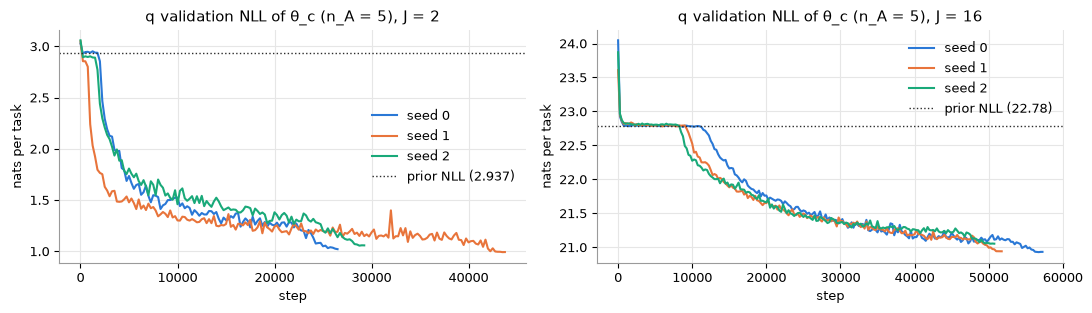

prior NLLs from the runs' stdout (val_prior_nll)


In [ ]:
tr = {"J = 2": ("pilot_20261103-120248", [0, 1, 2], 2.937), "J = 16": ("pilot_20261103-134243", [0, 1, 2], 22.78)}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, (lab, (sw, mem, prior)) in zip(axs, tr.items()):
    cv = load_snapshot(f"results/air_rb/{sw}").curves()
    cv = cv[(cv.key == "val/nll_n5") & cv.member.isin(mem)]
    for k, (m, g) in enumerate(cv.groupby("member")):
        ax.plot(g.step, g.value, color=C[k], lw=1.5, label=f"seed {m}")
    ax.axhline(prior, color=INK, ls=":", lw=1, label=f"prior NLL ({prior})")
    ax.set(title=f"q validation NLL of θ_c (n_A = 5), {lab}", xlabel="step", ylabel="nats per task")
    ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print("prior NLLs from the runs' stdout (val_prior_nll)")

### P3.1: q at Σ = 0 (SBC, HPD coverage, KL(π̂_D ‖ q)), J = 2

KS p-values per seed (SBC ranks out of 255 draws, jittered to the continuum); coverage = share of tasks whose true θ_c lies in the q-HPD region of that mass; KL on the cal_tasks grid subset.

,seed,n_a,sbc0_p,sbc1_p,cov50,cov90,kl_med,pass
0,0,1,0.328,0.911,0.500,0.918,0.064,True
1,0,2,0.801,0.534,0.488,0.879,0.144,False
2,0,3,0.315,0.057,0.477,0.867,0.173,False
3,0,5,0.895,0.591,0.461,0.898,0.223,False
4,0,10,0.502,0.201,0.551,0.957,0.342,False
5,1,1,0.407,0.977,0.520,0.898,0.038,True
6,1,2,0.563,0.300,0.488,0.891,0.095,True
7,1,3,0.327,0.583,0.477,0.891,0.138,False
8,1,5,0.829,0.853,0.543,0.906,0.174,False
9,1,10,0.678,0.487,0.559,0.938,0.208,False


P3.1 holds (all seeds, all n_A): False


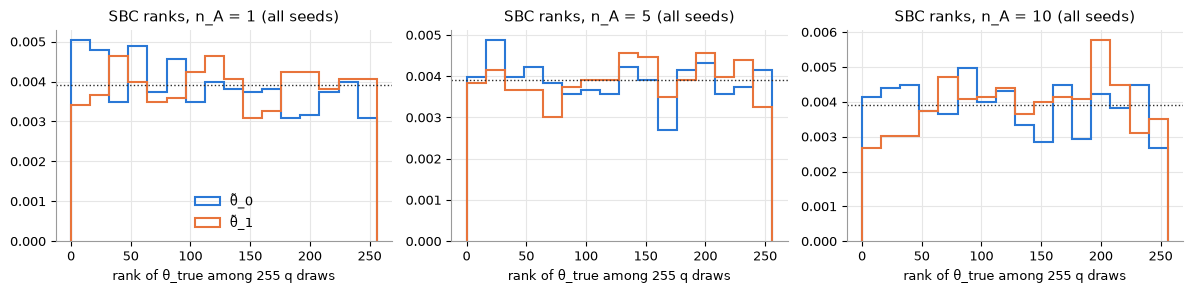

In [ ]:
d = DIAG[(DIAG.J == 2) & (DIAG.sig == 0.0)]
rng = np.random.default_rng(0)
rows = []
for (s, n), g in d.groupby(["seed", "n_a"]):
    r = {"seed": s, "n_a": n}
    for j in (0, 1):
        v = g[g.metric == f"sbc_rank_{j}"].value.to_numpy()
        r[f"sbc{j}_p"] = stats.kstest((v + rng.uniform(size=v.size)) / 256, "uniform").pvalue
    h = g[g.metric == "hpd"].value.to_numpy()
    r["cov50"], r["cov90"] = (h <= 0.5).mean(), (h <= 0.9).mean()
    r["kl_med"] = g[g.metric == "kl_dq"].value.median()
    rows.append(r)
p31 = pd.DataFrame(rows)
p31["pass"] = ((p31.sbc0_p > 0.01) & (p31.sbc1_p > 0.01) & ((p31.cov50 - 0.5).abs() <= 0.05)
               & ((p31.cov90 - 0.9).abs() <= 0.05) & (p31.kl_med < 0.1))
display(p31.round(3))
P31 = bool(p31["pass"].all())
print("P3.1 holds (all seeds, all n_A):", P31)
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for k, n in enumerate((1, 5, 10)):
    for j in (0, 1):
        v = d[(d.n_a == n) & (d.metric == f"sbc_rank_{j}")].value
        axs[k].hist(v, bins=16, range=(0, 256), histtype="step", color=C[j], lw=1.5, density=True, label=f"θ̃_{j}")
    axs[k].axhline(1 / 256, color=INK, ls=":", lw=1)
    axs[k].set(title=f"SBC ranks, n_A = {n} (all seeds)", xlabel="rank of θ_true among 255 q draws")
axs[0].legend(frameon=False); plt.tight_layout(); plt.show()

### P3.2: decoder-implied posterior calibration (PIT of θ̃_true under π̂_D), Σ = 0, J = 2

In [ ]:
rows = []
for (s, n), g in d.groupby(["seed", "n_a"]):
    r = {"seed": s, "n_a": n}
    for j in (0, 1):
        r[f"pit{j}_p"] = stats.kstest(g[g.metric == f"pit_{j}"].value.to_numpy(), "uniform").pvalue
    rows.append(r)
p32 = pd.DataFrame(rows); p32["pass"] = (p32.pit0_p > 0.01) & (p32.pit1_p > 0.01)
display(p32.round(4)); P32 = bool(p32["pass"].all()); print("P3.2 holds:", P32)

,seed,n_a,pit0_p,pit1_p,pass
0,0,1,0.9069,0.9978,True
1,0,2,0.1924,0.5298,True
2,0,3,0.1140,0.2525,True
3,0,5,0.4531,0.6612,True
4,0,10,0.1642,0.9115,True
5,1,1,0.8313,0.9956,True
6,1,2,0.2220,0.7855,True
7,1,3,0.3586,0.3128,True
8,1,5,0.4138,0.4803,True
9,1,10,0.0887,0.4828,True


P3.2 holds: True


### P3.3: K-curve at Σ = 0 (q-IS(K) − IS-ref), and NLL vs the references

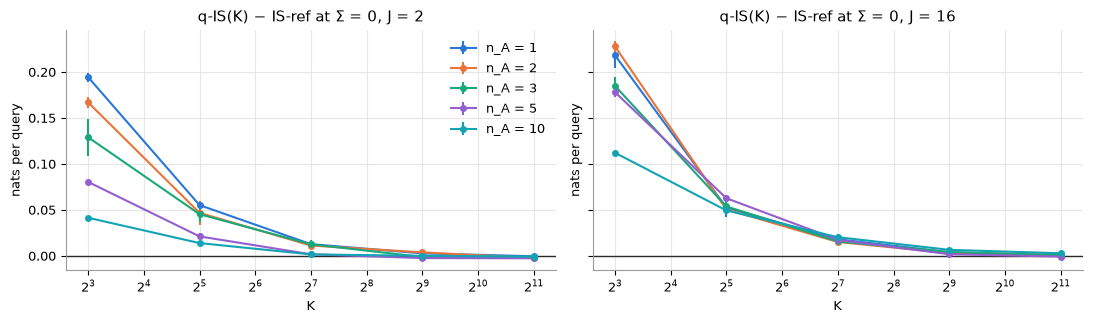

,mean,se
n_a,,
1,0.013,0.000
2,0.011,0.004
3,0.013,0.005
5,0.002,0.001
10,0.002,0.001


P3.3 holds: True


n_a                 1      2      3      5      10
J  method                                         
2  a_only_clean -0.874 -1.358 -1.613 -1.902 -2.178
   a_only_null  -0.870 -1.358 -1.618 -1.903 -2.190
   grid         -2.123 -2.293 -2.398 -2.517 -2.640
   isref        -2.011 -2.148 -2.236 -2.356 -2.493
   teacher      -2.549 -2.557 -2.562 -2.570 -2.588
16 a_only_clean -0.905 -1.360 -1.598 -1.850 -2.141
   a_only_null  -0.903 -1.359 -1.595 -1.848 -2.142
   isref        -1.950 -2.048 -2.120 -2.216 -2.330
   teacher      -2.476 -2.484 -2.492 -2.506 -2.521

In [ ]:
ks = [8, 32, 128, 512, 2048]
rows = []
for J in (2, 16):
    ref = per_seed("isref", -1.0, J)
    for K in ks:
        v = (per_seed(f"qis{K}", 0.0, J) - ref).rename("v").reset_index().assign(J=J, K=K)
        rows.append(v)
kc = seed_stats(pd.concat(rows))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
for ax, J in zip(axs, (2, 16)):
    for k, n in enumerate(sorted(NLL.n_a.unique())):
        z = kc.loc[(slice(None), J, slice(None))] if False else kc.xs(J, level="J").xs(n, level="n_a")
        ax.errorbar(z.index, z["mean"], yerr=z["se"].fillna(0), color=C[k], marker="o", ms=4, lw=1.5, label=f"n_A = {n}")
    ax.axhline(0, color=INK, lw=1); ax.set_xscale("log", base=2)
    ax.set(title=f"q-IS(K) − IS-ref at Σ = 0, J = {J}", xlabel="K", ylabel="nats per query")
axs[0].legend(frameon=False); plt.tight_layout(); plt.show()
g128 = kc.xs(128, level="K").xs(2, level="J")
display(g128[["mean", "se"]].round(3))
P33 = bool(((g128.loc[g128.index >= 2, "mean"] <= 0.03).all()) and (g128.loc[1, "mean"] <= 0.07))
print("P3.3 holds:", P33)
ref_tab = NLL[NLL.sig == -1.0].groupby(["J", "method", "n_a"]).nll.mean().unstack("n_a").round(3)
display(ref_tab)

### P3.4 (primary): AIR at its best Σ vs the clean A-only PFN, K ∈ {8, 32}

Gain = NLL(clean A-only) − NLL(AIR q-IS(K), Σ); positive = AIR better. Heatmap: seed-mean gain per (Σ, K) and n_A.

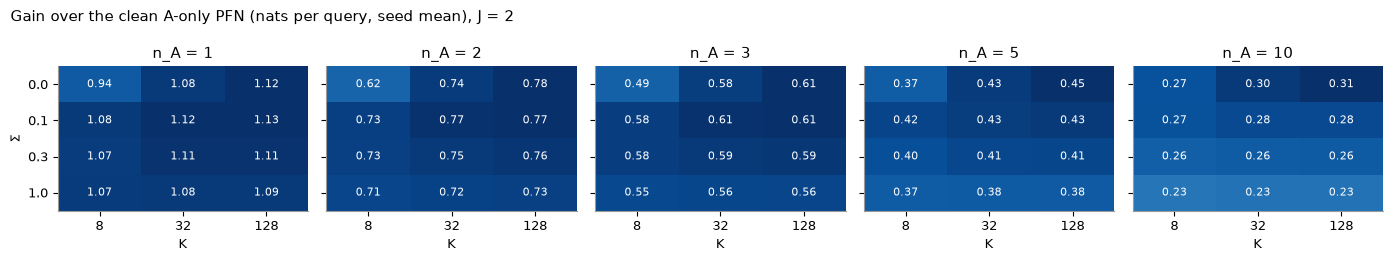

,K,best Σ,n_a,gain,pass
0,8,0.1,1,+1.079 ± 0.003,True
1,8,0.1,2,+0.731 ± 0.008,True
2,8,0.1,3,+0.576 ± 0.010,True
3,8,0.1,5,+0.415 ± 0.011,True
4,8,0.1,10,+0.272 ± 0.014,True
5,32,0.1,1,+1.118 ± 0.004,True
6,32,0.1,2,+0.770 ± 0.004,True
7,32,0.1,3,+0.606 ± 0.007,True
8,32,0.1,5,+0.428 ± 0.008,True
9,32,0.1,10,+0.282 ± 0.017,True


best Σ: {8: np.float64(0.1), 32: np.float64(0.1)} | P3.4 holds: True 
Paired NLL(Σ = 0) − NLL(best Σ), seed mean ± SE (positive = best Σ better):


mean            se       
K       8      32     8      32
n_a                            
1    0.136  0.036  0.003  0.005
2    0.108  0.027  0.011  0.015
3    0.081  0.028  0.027  0.014
5    0.042 -0.004  0.004  0.004
10  -0.001 -0.019  0.002  0.000

In [ ]:
sigs = sorted(s for s in NLL.sig.unique() if s >= 0)
base = per_seed("a_only_clean", -1.0, 2)
rows = []
for sg in sigs:
    for K in (8, 32, 128):
        m = per_seed(f"qis{K}", sg, 2)
        if len(m):
            rows.append((base - m).rename("v").reset_index().assign(sig=sg, K=K))
gain = seed_stats(pd.concat(rows))
nas = sorted(NLL.n_a.unique())
fig, axs = plt.subplots(1, len(nas), figsize=(14, 2.6), sharey=True)
for ax, n in zip(axs, nas):
    h = gain.xs(n, level="n_a")["mean"].unstack("K")
    im = ax.imshow(h.to_numpy(), cmap="Blues", aspect="auto", vmin=0)
    ax.set(xticks=range(h.shape[1]), xticklabels=h.columns, yticks=range(h.shape[0]), yticklabels=h.index,
           title=f"n_A = {n}", xlabel="K"); ax.grid(False)
    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            ax.text(j, i, f"{h.iat[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if h.iat[i, j] > 0.6 * np.nanmax(h.to_numpy()) else INK)
axs[0].set_ylabel("Σ")
fig.suptitle("Gain over the clean A-only PFN (nats per query, seed mean), J = 2", x=0.01, ha="left")
plt.tight_layout(); plt.show()
res, best = [], {}
for K in (8, 32):
    sel = NLL[(NLL.J == 2) & (NLL.n_a >= 2) & (NLL.method == f"qis{K}") & (NLL.sig >= 0)]
    best[K] = sel.groupby("sig").nll.mean().idxmin()
    z = gain.xs(best[K], level="sig").xs(K, level="K")
    for n, r in z.iterrows():
        res.append({"K": K, "best Σ": best[K], "n_a": n, "gain": fmt(r["mean"], r["se"]),
                    "pass": (n < 2) or (r["mean"] >= 0.05 and (NS < 2 or r["mean"] > 2 * r["se"]))})
p34 = pd.DataFrame(res); display(p34)
P34 = bool(p34[p34.n_a >= 2]["pass"].all()) and NS >= 3
print("best Σ:", best, "| P3.4 holds:", P34, "(needs 3 seeds)" if NS < 3 else "")
rows = []
for K in (8, 32):
    d0 = per_seed(f"qis{K}", 0.0, 2) - per_seed(f"qis{K}", best[K], 2)
    rows.append(d0.rename("v").reset_index().assign(K=K))
dd = seed_stats(pd.concat(rows))
print("Paired NLL(Σ = 0) − NLL(best Σ), seed mean ± SE (positive = best Σ better):")
display(dd[["mean", "se"]].unstack("K").round(3))

### P3.5: J scaling at the best Σ, K = 128

In [ ]:
sb = best[32]
ess = DIAG[(DIAG.J == 16) & (DIAG.metric == "ess_isref")].groupby("n_a").value.median()
rows = []
for J in (2, 16):
    rows.append((per_seed("qis128", sb, J) - per_seed("isref", -1.0, J)).rename("v").reset_index().assign(J=J))
gj = seed_stats(pd.concat(rows))["mean"].unstack("J")
gj["J16 − J2"] = gj[16] - gj[2]; gj["median ESS isref (J=16)"] = ess
gj["counts"] = gj["median ESS isref (J=16)"] >= 500
display(gj.round(3))
P35 = bool((gj.loc[gj.counts, "J16 − J2"] <= 0.05).all()) and gj.counts.any()
print(f"Σ = {sb}; P3.5 holds:", P35)

J,2,16,J16 − J2,median ESS isref (J=16),counts
n_a,,,,,
1,0.011,0.002,-0.010,3253.508,True
2,0.016,0.003,-0.013,2611.766,True
3,0.015,0.004,-0.012,2132.574,True
5,0.021,0.005,-0.016,1455.081,True
10,0.033,0.005,-0.029,771.484,True


Σ = 0.1; P3.5 holds: True


### P3.6: QMC vs i.i.d. at equal K (reported, no threshold)

In [ ]:
rows = []
for J in (2, 16):
    for K in (8, 32):
        for sg in sigs:
            a, b = per_seed(f"qis{K}", sg, J), per_seed(f"qmc{K}", sg, J)
            if len(a) and len(b):
                rows.append((a - b).rename("v").reset_index().assign(J=J, K=K, sig=sg))
q6 = seed_stats(pd.concat(rows))
print("NLL(i.i.d.) − NLL(QMC); positive = QMC better")
display(q6["mean"].unstack("n_a").round(3))

NLL(i.i.d.) − NLL(QMC); positive = QMC better


n_a           1      2      3      5      10
J  K  sig                                   
2  8  0.0  0.058  0.064  0.042  0.030  0.015
      0.1  0.031  0.035  0.031  0.016  0.010
      0.3  0.037  0.024  0.011  0.012  0.003
      1.0  0.008  0.010  0.004  0.002  0.001
   32 0.0  0.036  0.030  0.031  0.008  0.009
      0.1  0.011  0.010  0.006  0.005  0.001
      0.3  0.005  0.013  0.006  0.003  0.002
      1.0  0.004  0.006  0.002  0.003 -0.001
16 8  0.0  0.024  0.086  0.041  0.043  0.006
      0.1  0.017  0.038  0.017  0.013  0.008
      0.3  0.024  0.024  0.014  0.004 -0.001
      1.0  0.015  0.011  0.007  0.008  0.001
   32 0.0  0.004  0.013  0.014  0.013  0.005
      0.1  0.003  0.008  0.009  0.006  0.001
      0.3  0.012  0.008  0.006  0.006  0.001
      1.0  0.004  0.004  0.006  0.001 -0.000

### ESS/K by Σ and K

In [ ]:
e = DIAG[DIAG.metric.str.startswith("ess_q")].copy()
e["K"] = e.metric.str.extract(r"(\d+)").astype(int); e["kind"] = e.metric.str.extract(r"ess_(q\w\w)")
display(e[e.kind == "qis"].groupby(["J", "sig", "K"]).value.median().unstack("K").round(2))

K       8     32    128   512   2048
J  sig                              
2  0.0  0.78  0.73  0.72  0.72  0.72
   0.1  0.88  0.85  0.84   NaN   NaN
   0.3  0.90  0.88  0.88   NaN   NaN
   1.0  0.93  0.91  0.91   NaN   NaN
16 0.0  0.65  0.57  0.54  0.52  0.51
   0.1  0.79  0.75  0.73   NaN   NaN
   0.3  0.83  0.80  0.78   NaN   NaN
   1.0  0.87  0.83  0.80   NaN   NaN

### Example PPDs (seed 0 checkpoints; J = 2, Σ = best, K = 128; tasks drawn on CPU, so not the evaluation tasks with the same ids)

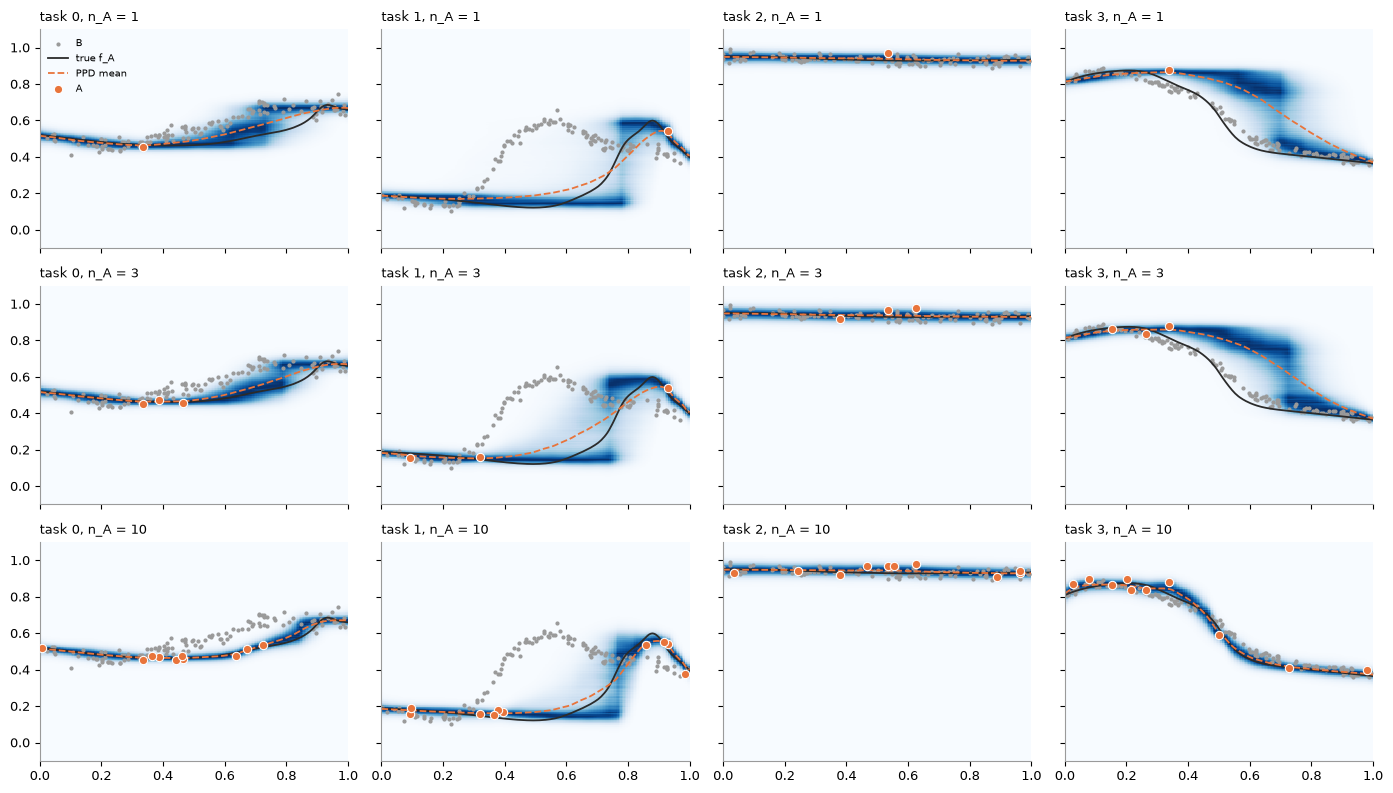

In [ ]:
import dataclasses
from pathlib import Path
import torch
from meta_pfn.experimental.air.decoder import N_BINS, Y_HI, Y_LO, Decoder
from meta_pfn.experimental.air.estimator import importance
from meta_pfn.experimental.air.prior import flow
from meta_pfn.experimental.air.proposal import Proposal
from meta_pfn.experimental.air.train import eval_tasks
from meta_pfn.utils.env import repo_root
R = repo_root() / "runs/air_rb"
DEC = R / "pilot_20261103-101808/0/tracking/artifacts/model.pt"
Q2 = R / "pilot_20261103-120248/0/tracking/artifacts/model.pt"
if not (DEC.exists() and Q2.exists()):
    print("Seed-0 checkpoints not found under runs/air_rb/: rsync them to draw the examples.")
else:
    torch.manual_seed(0)
    dec = Decoder(D=128, layers=6, sig_cond=True); dec.load_state_dict(torch.load(DEC, map_location="cpu")); dec.eval()
    q = Proposal(2, sig_cond=True); q.load_state_dict(torch.load(Q2, map_location="cpu")); q.eval()
    XS = torch.linspace(0, 1, 200)
    CEN = (torch.linspace(Y_LO, Y_HI, N_BINS + 1)[:-1] + (Y_HI - Y_LO) / N_BINS / 2).numpy()
    sg = float(best[32])

    @torch.no_grad()
    def ppd(t, K=128):
        tg = dataclasses.replace(t, xq=XS[None], yq=torch.zeros(1, len(XS)), fq=torch.zeros(1, len(XS)))
        th, lqm = q.sample_mix(t.xb, t.yb, t.xa, t.ya, K, sig=sg)
        w = importance(dec, tg, th, lqm, sig=sg)["lw"][0].softmax(-1)
        xb_t = flow(t.xb.expand(K, -1), th[0], t.s_t, inverse=True)
        rep = lambda z: z.expand(K, -1)  # noqa: E731
        lg, _ = dec(xb_t, rep(t.yb), rep(t.xa), rep(t.ya), rep(XS[None]), sig=torch.full((K,), sg))
        return (w[:, None, None] * lg.softmax(-1)).sum(0).numpy()

    base = eval_tasks(2, 8, 777, "cpu", g_norm="ecdf")
    fig, axs = plt.subplots(3, 4, figsize=(14, 8), sharex=True, sharey=True)
    for c in range(4):
        ti = base.sub(slice(c, c + 1))
        for r, n in enumerate((1, 3, 10)):
            t = ti.head(n); p = ppd(t); ax = axs[r, c]
            ax.imshow((p / p.max(1, keepdims=True)).T, origin="lower", aspect="auto", extent=[0, 1, Y_LO, Y_HI],
                      cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
            ax.scatter(t.xb[0], t.yb[0], s=4, color="#9a9a9a", label="B")
            ax.plot(XS, t.g(flow(XS[None], t.theta, t.s_t))[0], color=INK, lw=1.3, label="true f_A")
            ax.plot(XS, p @ CEN, color=C[1], lw=1.3, ls="--", label="PPD mean")
            ax.scatter(t.xa[0], t.ya[0], s=36, color=C[1], edgecolor="white", lw=.8, zorder=3, label="A")
            ax.set(ylim=(-0.1, 1.1)); ax.grid(False)
            ax.set_title(f"task {c}, n_A = {n}", loc="left", fontsize=9)
    axs[0, 0].legend(frameon=False, fontsize=7, loc="upper left")
    plt.tight_layout(); plt.show()

### Pilot-2 diagnostics recap (`results/air/pilot_20261103-122813`, notebook 10)

- Finite-K loss at J = 2, n_A = 1: 0.18 nats (0.66 in pilot 1): the warm-started proposal removed most of it.
- q-IS saturates at K ≈ 128: beyond it the NLL does not move (the remaining gap is the decoder, not the sampler).
- Decoder gap to G-ref (exact dense-B reference) of about 0.1–0.2 nats, roughly constant in n_A.

### Criteria summary

In [ ]:
summ = pd.DataFrame([("P3.1 q calibration (Σ = 0)", P31), ("P3.2 decoder posterior calibration", P32),
                     ("P3.3 K-curve", P33), ("P3.4 primary: best Σ vs clean A-only", P34), ("P3.5 J scaling", P35),
                     ("P3.6 QMC", "reported")], columns=["criterion", "holds"])
display(summ)
print("best Σ at K = 32:", best[32], "| seeds:", SEEDS)

,criterion,holds
0,P3.1 q calibration (Σ = 0),False
1,P3.2 decoder posterior calibration,True
2,P3.3 K-curve,True
3,P3.4 primary: best Σ vs clean A-only,True
4,P3.5 J scaling,True
5,P3.6 QMC,reported


best Σ at K = 32: 0.1 | seeds: [np.int64(0), np.int64(1), np.int64(2)]


## Interpretation (3 seeds, 2026-11-03)

Evaluation snapshots `results/air_rb/pilot_20261103-184131` (seed 0), `pilot_20261103-211850` (seed 1),
`pilot_20261103-160447` (seed 2); all members DONE (2 per sweep, one per J), none failed, started or missing.
± = SE across the 3 seeds (training variability; the 256 tasks per cell are shared).

**Primary (P3.4): passes.** At the best Σ (0.1, at both K = 8 and K = 32) AIR beats the clean A-only PFN by
+0.77 / +0.61 / +0.43 / +0.28 nats per query at n_A = 2 / 3 / 5 / 10 (K = 32; SE ≤ 0.017), and by +1.12 at n_A = 1.
At K = 8 the gains are nearly as large (+0.73 … +0.27). Dense B, read through an explicit transform latent, is worth a
lot to the scarce task, and it is worth it at small K.

**Σ > 0 pays, but mainly at small K and small n_A.** Paired NLL(Σ = 0) − NLL(Σ = 0.1): +0.14 / +0.11 / +0.08 nats at
n_A = 1 / 2 / 3 for K = 8, but only +0.03–0.04 at K = 32, and slightly negative at n_A = 10 (−0.02 at K = 32). Σ widens
the posterior the proposal has to hit, so it helps when K is too small for the sharp Σ = 0 posterior, and costs a
little where the data pin θ down. Σ = 0.1 was selected on the same tasks it is scored on (4 candidates; the margin at
K = 32 is small).

**Where the remaining gap is.** At J = 2, AIR (K = 32, Σ = 0.1) is 0.13–0.19 nats above the exact G-ref. Of that,
isref − grid = 0.11–0.16 nats is the decoder (same likelihood, K = 4096 prior IS), so the proposal at K = 32 costs only
0.02–0.03 nats. The next nats are in the decoder, not the sampler (as pilot 2 already suggested).

**Sampler criteria.** P3.3 passes (q-IS(128) − IS-ref ≤ 0.013 at every n_A). P3.5 passes: at J = 16 the q-IS gap is
smaller than at J = 2 (J16 − J2 between −0.03 and −0.01), with the J = 16 IS-ref median ESS ≥ 770 in every cell; the
J = 16 proposals, retrained with the initial-plateau guard, work. QMC (P3.6) helps by 0.01–0.09 nats at K = 8 and by
≤ 0.03 at K = 32, mostly at Σ = 0.

**P3.1 fails, and how.** SBC KS p > 0.05 for both coordinates in every cell and 50/90 % HPD coverage within the ±5
points, so q is *calibrated*. What fails is median KL(π̂_D ‖ q): 0.04–0.07 at n_A = 1 but 0.10–0.34 at n_A ≥ 2 (pass
< 0.1), growing with n_A in every seed. q is calibrated but too wide/mis-shaped relative to the decoder posterior as
the data sharpen it, the same under-fit seen in pilot 2 (KL 0.94 at n_A = 5 then). It costs little in NLL here because
importance weights correct it (ESS/K 0.72–0.85 at J = 2), but it is what limits ESS at small K and larger n_A. This is
the target of proposal v2 (#21, notebook 14). P3.2 passes: the decoder's implied posterior is calibrated (PIT p ≥ 0.09).

**Comparison with MTPFN (notebook 13), provisional.** MTPFN's diagnostics so far ran on other task samples (see
notebook 13), so only an unpaired comparison is possible: there MTPFN gains +0.94 / +0.49 / +0.22 over the same clean
A-only PFN at n_A = 1 / 3 / 10 and sits 0.20–0.24 nats above G-ref, versus AIR's +1.12 / +0.61 / +0.28 and
0.13–0.18 here. The paired comparison on these exact tasks is queued (MTPFN air_diag on GPU with 256 tasks).

**Proposed verdict (decision rule 1).** P3.4 passes and the best Σ at K = 32 is 0.1 > 0 → **GO: continue with AIR at
Σ = 0.1 to h (V7) and d = 2.** Caveats to carry: P3.1's KL failure (q under-fit as n_A grows), Σ selected on the
scoring tasks with a small margin at K = 32, d = 1 / Z0 / H0 only.


## Verdict

Proposed in the interpretation above; recorded by the user with `just decide`.